# Pipeline agentico: tool-calling + vision + RPA

Primera prueba de extremo a extremo del patron que vamos a usar para el agente (fase 3-4 de `PROJECT.md`): un LLM orquestador con **tool-calling real** decide, a partir de una instruccion en lenguaje natural, que herramientas llamar y con que argumentos -- nosotros definimos esas herramientas como funciones Python normales.

```
instruccion en lenguaje natural
        |
        v
  orquestador (GPT-OSS-120B via Groq, tool-calling nativo)
        |-- localizar_elemento(descripcion)
        |       captura de pantalla (mss) + UI-TARS (vision_tools.py) -> (x, y)
        |
        `-- click(x, y)
                pyautogui.click(x, y)  <- el clic real
```

UI-TARS **no** es el orquestador: no tiene tool-calling nativo, devuelve texto plano en su propio formato de accion. Por eso vive escondido dentro de la tool `localizar_elemento`, y quien decide la secuencia de llamadas es el modelo de Groq.

Objetivo de esta prueba: que el agente, a partir de "haz clic en el boton Entrar", localice el boton solo y haga clic de verdad sobre la ventana real de GestCorp 98.

In [13]:
# En Windows, si el proceso no se declara "DPI aware" las coordenadas que
# usa pyautogui pueden no coincidir 1:1 con los pixeles reales que captura
# mss (la pantalla se ve escalada de forma distinta para cada uno). Hay que
# hacer esto ANTES de usar mss/pyautogui, lo antes posible en el kernel.
import ctypes

try:
    ctypes.windll.shcore.SetProcessDpiAwareness(1)  # PROCESS_SYSTEM_DPI_AWARE
except Exception as exc:
    print(f"no se pudo fijar DPI awareness (quiza no es Windows): {exc}")

In [14]:
import os

from dotenv import load_dotenv

load_dotenv("../.env")  # carga GROQ_API_KEY desde el .env en la raiz del proyecto

assert os.environ.get("GROQ_API_KEY"), (
    "Falta GROQ_API_KEY. Rellena la clave en el archivo .env de la raiz del "
    "proyecto (la consigues en https://console.groq.com/) y vuelve a "
    "ejecutar esta celda."
)


## Las dos tools

`localizar_elemento` envuelve `vision_tools.localizar_elemento_en_pantalla` (la misma logica de UI-TARS ya validada en `vision_evaluation.ipynb`, extraida a un modulo aparte para no duplicarla). `click` ejecuta el clic real con `pyautogui`. El docstring de cada tool es lo que el LLM orquestador lee para decidir cuando usarla -- tiene que ser claro.

In [15]:
import pyautogui
from langchain_core.tools import tool

import vision_tools


@tool
def localizar_elemento(descripcion: str) -> dict:
    """Localiza un elemento de la interfaz visible AHORA MISMO en pantalla,
    a partir de su descripcion en lenguaje natural (p.ej. "el boton Entrar",
    "el campo de texto Usuario"). Hace una captura de pantalla real y usa un
    modelo de vision para encontrarlo. Devuelve las coordenadas de pantalla
    (x, y) donde hacer clic.
    """
    resultado = vision_tools.localizar_elemento_en_pantalla(descripcion)
    return {"x": resultado["x"], "y": resultado["y"]}


@tool
def click(x: int, y: int) -> str:
    """Hace clic con el boton izquierdo del raton en las coordenadas de
    pantalla (x, y) dadas. Usa primero `localizar_elemento` para obtener
    las coordenadas de lo que quieras clicar.
    """
    pyautogui.click(x, y)
    return f"clic hecho en ({x}, {y})"

## El orquestador: LangChain v1 (`create_agent`) + GPT-OSS-120B (Groq)

`create_agent` (API de agentes de `langchain` v1, sobre LangGraph por debajo) monta el bucle estandar (el LLM decide una tool -> se ejecuta de verdad -> el resultado vuelve al LLM -> repite hasta que ya no hace falta mas) sin tener que escribir el grafo a mano.

In [16]:
from langchain.agents import create_agent
from langchain_groq import ChatGroq

model = ChatGroq(model="openai/gpt-oss-120b", temperature=0)
agent = create_agent(
    model,
    tools=[localizar_elemento, click],
    system_prompt=(
        "Eres un agente de RPA. Para cada instruccion, localiza primero el "
        "elemento con `localizar_elemento` y luego actua sobre el con la "
        "tool correspondiente (p.ej. `click`). No inventes coordenadas: "
        "usa siempre las que te devuelva `localizar_elemento`."
    ),
)


## Lanzar GestCorp 98 y ejecutar el agente, todo en una sola celda

Como proceso aparte (si fuera en el mismo proceso, `root.mainloop()` de Tkinter bloquearia el kernel de Jupyter).

Importante: lanzar la app y correr el agente **en celdas separadas** es justo lo que causaba el fallo (el agente clicaba sobre lo que tuvieras delante en ese momento -- p.ej. VSCode -- porque entre una celda y otra el foco se queda donde tu lo dejes). Por eso aqui va todo junto: se abre la ventana, se le fuerza el foco con `pygetwindow` antes de que el agente haga nada, se invoca al agente, y se verifica con una captura -- sin que tengas que tocar nada entre medias.

Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


================================ Human Message =================================

Haz clic en el boton 'Entrar' de la ventana de GestCorp 98 que esta abierta en pantalla ahora mismo.
================================== Ai Message ==================================
Tool Calls:
  localizar_elemento (fc_8fd1d4df-3518-42a3-898e-ff9d27f4c1ff)
 Call ID: fc_8fd1d4df-3518-42a3-898e-ff9d27f4c1ff
  Args:
    descripcion: botón Entrar de la ventana de GestCorp 98
================================= Tool Message =================================
Name: localizar_elemento

{"x": 223, "y": 314}
================================== Ai Message ==================================
Tool Calls:
  click (fc_3139401d-8690-4206-8a3c-c81c8fbe1985)
 Call ID: fc_3139401d-8690-4206-8a3c-c81c8fbe1985
  Args:
    x: 223
    y: 314
================================= Tool Message =================================
Name: click

clic hecho en (223, 314)
================================== Ai Message ============================

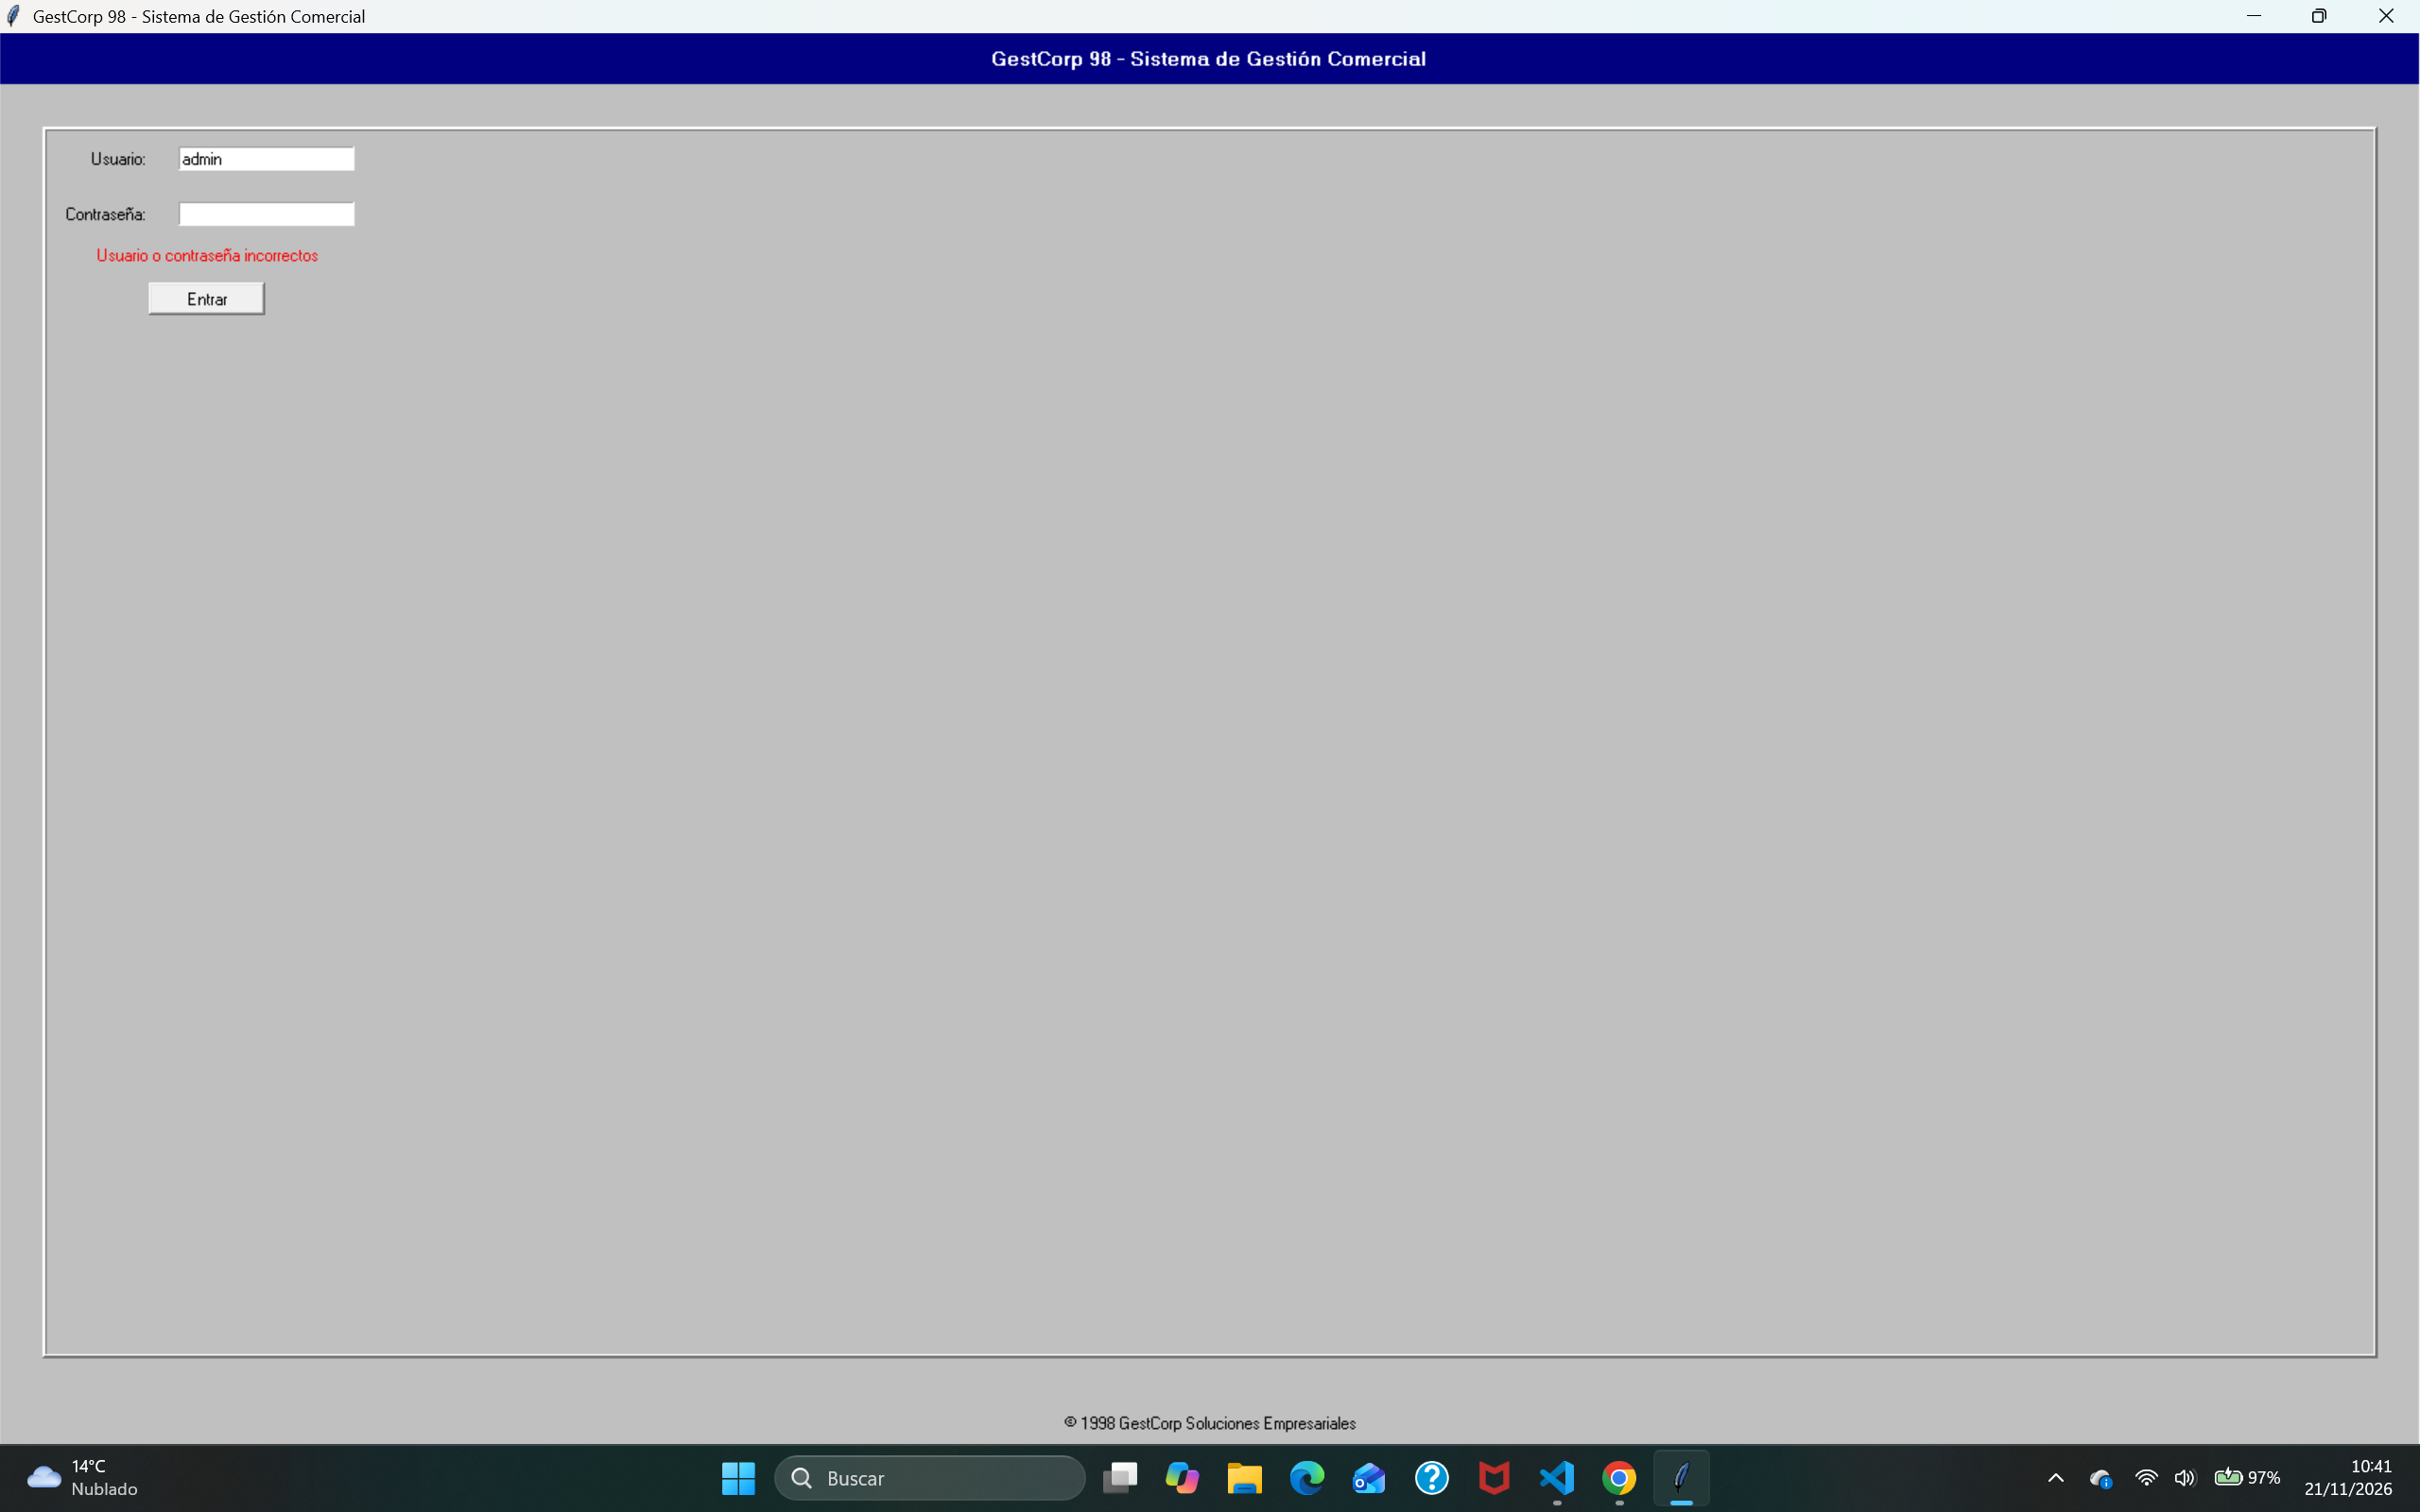

In [17]:
import subprocess
import sys
import time

import pygetwindow as gw

TITULO_VENTANA = "GestCorp 98 - Sistema de Gestión Comercial"

proceso_gestcorp98 = subprocess.Popen([sys.executable, "-m", "gestcorp98.main"], cwd="..")

# esperar a que la ventana aparezca y FORZARLE el foco -- si no, el clic cae
# sobre lo que tengas delante en ese momento (p.ej. VSCode), que es
# exactamente lo que paso antes
ventana = None
for _ in range(20):
    time.sleep(0.5)
    candidatas = gw.getWindowsWithTitle(TITULO_VENTANA)
    if candidatas:
        ventana = candidatas[0]
        break
if ventana is None:
    raise RuntimeError(f"no encontre la ventana '{TITULO_VENTANA}' tras 10s")

try:
    if ventana.isMinimized:
        ventana.restore()
    ventana.activate()
except Exception as exc:
    # pygetwindow a veces lanza aqui aunque el cambio de foco SI funcione
    # (restriccion de Windows sobre que proceso puede robar el foco) -- no
    # cortamos la ejecucion por esto, solo avisamos
    print(f"aviso: activate() lanzo un error ({exc}), sigo de todas formas")
time.sleep(1)  # dar tiempo a que el foco cambie de verdad

respuesta = agent.invoke(
    {
        "messages": [
            (
                "user",
                "Haz clic en el boton 'Entrar' de la ventana de GestCorp 98 "
                "que esta abierta en pantalla ahora mismo.",
            )
        ]
    }
)

for m in respuesta["messages"]:
    m.pretty_print()

time.sleep(1)  # dar tiempo a que la UI reaccione al clic
vision_tools.capturar_pantalla()


## Limpieza

Cierra el proceso de GestCorp 98 cuando termines de probar.

In [18]:
proceso_gestcorp98.terminate()